# **PUMP IT UP 3 - JAIME DE VERA MARTÍN**

---

---



## Me conecto a Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Descargo las librerías necesarias

In [2]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.1 MB/s eta 0:00:00


## Importo las librerías necesarias

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier

from sklearn.cluster import KMeans
import lightgbm as lgb

from catboost import CatBoostClassifier

## Me creo mis DataFrames principales

In [4]:
X_train_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TrainingSetValues.csv',
                          sep=',',
                          index_col='id',
                          parse_dates=['date_recorded'])

y_train_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TrainingSetLabels.csv',
                          sep=',',
                          index_col='id')

X_test_original = pd.read_csv(r'/content/drive/MyDrive/Machine Learning/Tarea/Conjuntos de datos/TestSetValues.csv',
                          sep=',',
                          index_col='id',
                          parse_dates=['date_recorded'])

# Mapeo de la variable objetivo a formato numérico
y = y_train_original["status_group"].map({'non functional': 0, 'functional needs repair': 1, 'functional': 2})

print(f"Dimensiones de entrenamiento original: {X_train_original.shape}")

Dimensiones de entrenamiento original: (59400, 39)


## **LIMPIEZA Y PREPROCESADO**


In [5]:
def preprocesado_v3(df):
    df_clean = df.copy()

    # Antigüedad
    df_clean['antiguedad'] = df_clean['date_recorded'].dt.year - df_clean['construction_year']
    df_clean.drop(columns=['date_recorded', 'construction_year'], inplace=True)

    # Caza de ceros (solo en coordenadas)
    for col in ['longitude', 'latitude']:
        df_clean[col] = df_clean[col].replace(0, np.nan)
        if col == 'latitude':
            df_clean[col] = df_clean[col].apply(lambda x: np.nan if x > -1e-6 else x)

    df_clean['antiguedad'] = df_clean['antiguedad'].apply(lambda x: np.nan if x > 100 else x)

    # Borrado de ruido inútil
    columnas_borrar = [
        'recorded_by', 'num_private', 'scheme_name', 'subvillage', 'ward', 'lga',
        'extraction_type_group', 'extraction_type_class', 'management_group',
        'scheme_management', 'payment_type', 'quality_group', 'quantity_group',
        'source_type', 'source_class', 'waterpoint_type_group']

    df_clean.drop(columns=columnas_borrar, inplace=True, errors='ignore')

    return df_clean

X_clean = preprocesado_v3(X_train_original)

# Separación
X_train, X_val, y_train, y_val = train_test_split(X_clean, y, test_size=0.2, random_state=42, stratify=y)
print(f"Dimensiones de entrenamiento: {X_train.shape}")

Dimensiones de entrenamiento: (47520, 22)


## **MODELADO (XGBOOST CON TARGET ENCODING)**

XGBoost es un algoritmo de Gradient Boosting que construye árboles de forma secuencial. Usaremos `TargetEncoder` para las variables de alta cardinalidad.

In [6]:
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()

cat_high = ['funder', 'installer', 'wpt_name']
cat_low = [col for col in X_train.select_dtypes(exclude=[np.number]).columns if col not in cat_high]

# Transformadores
num_transformer = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
cat_transformer = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
target_transformer = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('target_enc', TargetEncoder(smooth="auto"))])

preprocessor_xgb = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat_low', cat_transformer, cat_low),
    ('cat_high', target_transformer, cat_high)])

# Pipeline y entrenamiento
pipeline_xgb = Pipeline([
    ('preprocessor', preprocessor_xgb),
    ('classifier', XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=10, random_state=42, n_jobs=-1))])

pipeline_xgb.fit(X_train, y_train)
print(f"Precisión XGBoost en validación: {pipeline_xgb.score(X_val, y_val):.4f}")

Precisión XGBoost en validación: 0.8071


## **INTERPRETABILIDAD DE XGBOOST**

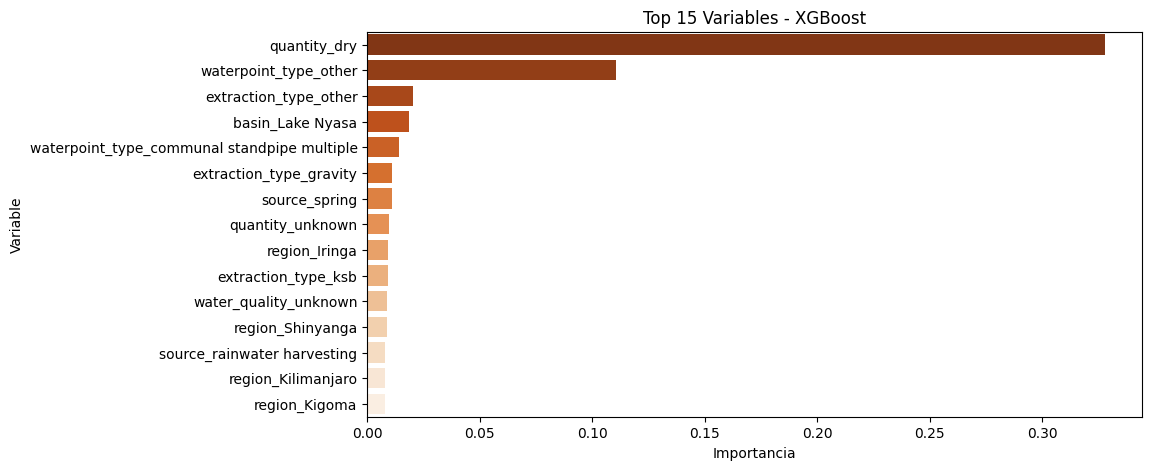

In [7]:
nombres_xgb = [n.split('__')[-1] for n in pipeline_xgb.named_steps['preprocessor'].get_feature_names_out()]
importancias_xgb = pipeline_xgb.named_steps['classifier'].feature_importances_

df_imp_xgb = pd.DataFrame({'Variable': nombres_xgb, 'Importancia': importancias_xgb}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importancia', y='Variable', data=df_imp_xgb.head(15), palette='Oranges_r', hue='Variable', legend=False)
plt.title('Top 15 Variables - XGBoost')
plt.show()

## **PREDICCIÓN Y EXPORTACIÓN DEL MODELO XGBOOST**

In [8]:
X_test_xgb = preprocesado_v3(X_test_original)
pred_xgb = pipeline_xgb.predict(X_test_xgb)

mapeo_inverso = {0: 'non functional', 1: 'functional needs repair', 2: 'functional'}
df_sub_xgb = pd.DataFrame({'id': X_test_original.index, 'status_group': pd.Series(pred_xgb).map(mapeo_inverso)})

#df_sub_xgb.to_csv('xgboost_v3_submission.csv', index=False)

df_sub_xgb.head(5)

,id,status_group
0,50785,non functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional


## **MODELO LIGHTGBM**

Utilizamos K-Means para agrupar las coordenadas GPS en 10 clústeres geográficos definidos por la densidad de los datos. LightGBM aprovecha esta nueva variable para identificar regiones problemáticas de forma más eficiente.

In [9]:
coord_train = X_train[['longitude', 'latitude']].fillna(X_train[['longitude', 'latitude']].median())
coord_val = X_val[['longitude', 'latitude']].fillna(X_train[['longitude', 'latitude']].median())

kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
X_train_lgb = X_train.copy()
X_val_lgb = X_val.copy()

X_train_lgb['geo_cluster'] = kmeans.fit_predict(coord_train).astype(str)
X_val_lgb['geo_cluster'] = kmeans.predict(coord_val).astype(str)

cat_low_lgb = cat_low + ['geo_cluster']
preprocessor_lgb = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat_low', cat_transformer, cat_low_lgb),
    ('cat_high', target_transformer, cat_high)])

pipeline_lgb = Pipeline([
    ('preprocessor', preprocessor_lgb),
    ('classifier', lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, max_depth=15, random_state=42, n_jobs=-1, verbose=-1))])

pipeline_lgb.fit(X_train_lgb, y_train)
print(f"Precisión LightGBM en validación: {pipeline_lgb.score(X_val_lgb, y_val):.4f}")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Precisión LightGBM en validación: 0.7997


## **INTERPRETABILIDAD LIGHTGBM**

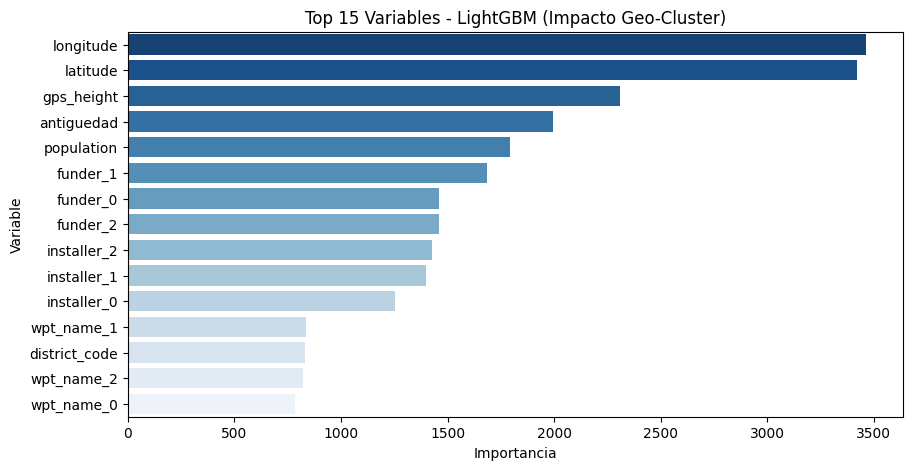

In [10]:
nombres_lgb = [n.split('__')[-1] for n in pipeline_lgb.named_steps['preprocessor'].get_feature_names_out()]
importancias_lgb = pipeline_lgb.named_steps['classifier'].feature_importances_

df_imp_lgb = pd.DataFrame({'Variable': nombres_lgb, 'Importancia': importancias_lgb}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importancia', y='Variable', data=df_imp_lgb.head(15), palette='Blues_r', hue='Variable', legend=False)
plt.title('Top 15 Variables - LightGBM (Impacto Geo-Cluster)')
plt.show()

## **PREDICCIÓN Y EXPORTACIÓN DEL MODELO LIGHTGBM**

In [11]:
X_test_lgb = preprocesado_v3(X_test_original)
coord_test = X_test_lgb[['longitude', 'latitude']].fillna(X_train[['longitude', 'latitude']].median())
X_test_lgb['geo_cluster'] = kmeans.predict(coord_test).astype(str)

pred_lgb = pipeline_lgb.predict(X_test_lgb)
df_sub_lgb = pd.DataFrame({'id': X_test_original.index, 'status_group': pd.Series(pred_lgb).map(mapeo_inverso)})

#df_sub_lgb.to_csv('lightgbm_v3_submission.csv', index=False)
df_sub_lgb.head(5)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,id,status_group
0,50785,functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional


# **MODELO CATBOOST**

El algoritmo de CatBoost gestiona el texto directamente, por lo que no usaremos One-Hot ni Target Encoding externos. Simplemente dejaremos que el modelo descubra las relaciones por sí mismo.

In [12]:
X_train_cat = X_train_lgb.copy()
X_val_cat = X_val_lgb.copy()
cat_features = X_train_cat.select_dtypes(exclude=[np.number]).columns.tolist()

X_train_cat[cat_features] = X_train_cat[cat_features].fillna('None').astype(str)
X_val_cat[cat_features] = X_val_cat[cat_features].fillna('None').astype(str)

model_cat = CatBoostClassifier(iterations=700, learning_rate=0.05, depth=8,
                               cat_features=cat_features, verbose=100, random_seed=42)

model_cat.fit(X_train_cat, y_train, eval_set=(X_val_cat, y_val), early_stopping_rounds=50)
print(f"Precisión CatBoost en validación: {accuracy_score(y_val, model_cat.predict(X_val_cat)):.4f}")

0:	learn: 1.0594066	test: 1.0594700	best: 1.0594700 (0)	total: 1.57s	remaining: 18m 19s
100:	learn: 0.5557530	test: 0.5523596	best: 0.5523596 (100)	total: 3m 2s	remaining: 17m 59s
200:	learn: 0.5226619	test: 0.5294078	best: 0.5294078 (200)	total: 5m 46s	remaining: 14m 19s
300:	learn: 0.5018146	test: 0.5187840	best: 0.5187840 (300)	total: 8m 25s	remaining: 11m 9s
400:	learn: 0.4868702	test: 0.5127085	best: 0.5127020 (399)	total: 11m 9s	remaining: 8m 19s
500:	learn: 0.4749448	test: 0.5089387	best: 0.5089387 (500)	total: 13m 49s	remaining: 5m 29s
600:	learn: 0.4632510	test: 0.5056717	best: 0.5056717 (600)	total: 16m 30s	remaining: 2m 43s
699:	learn: 0.4529914	test: 0.5032691	best: 0.5032691 (699)	total: 19m 8s	remaining: 0us

bestTest = 0.503269059
bestIteration = 699

Precisión CatBoost en validación: 0.7944


## **INTERPRETABILIDAD CATBOOST**

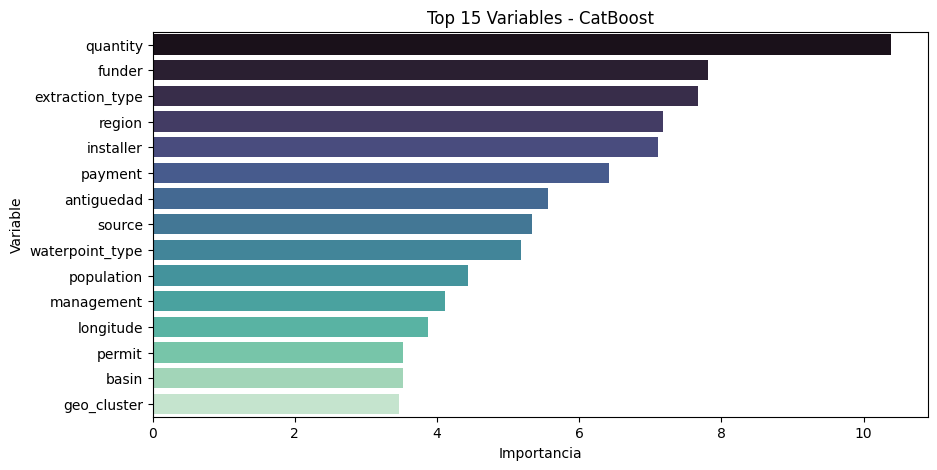

In [13]:
df_imp_cat = pd.DataFrame({
    'Variable': model_cat.feature_names_,
    'Importancia': model_cat.get_feature_importance()
}).sort_values(by='Importancia', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importancia', y='Variable', data=df_imp_cat.head(15), palette='mako', hue='Variable', legend=False)
plt.title('Top 15 Variables - CatBoost')
plt.show()

## **PREDICCIÓN Y EXPORTACIÓN DEL MODELO LIGHTGBM**

In [14]:
X_test_cat = X_test_lgb.copy()
X_test_cat[cat_features] = X_test_cat[cat_features].fillna('None').astype(str)

pred_cat = model_cat.predict(X_test_cat).flatten()
df_sub_cat = pd.DataFrame({'id': X_test_original.index, 'status_group': pd.Series(pred_cat).map(mapeo_inverso)})

#df_sub_cat.to_csv('catboost_v3_submission.csv', index=False)
df_sub_cat.head(5)

,id,status_group
0,50785,functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional
